## NER атрибутов товара
Карточки товаров в каталоге часто содержат важные атрибуты — цвет, материал, длину, размер, — прямо в тексте названия или описания, но эти значения не всегда вынесены в отдельные структурированные поля и могут быть указаны в разной форме (например, «изумрудный» и «зелёный», «100 см» и «1 м»). Автоматическое извлечение и приведение атрибутов к каноническому виду упрощает поиск, фильтрацию и сопоставление товаров в каталоге.

Задача: на неразмеченных русскоязычных карточках товаров извлечь канонические значения атрибутов: цвет, материал, длина и размер (задача Named Entity Recognition)

In [32]:
!pip install -q sklearn-crfsuite


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import sklearn_crfsuite
from sklearn_crfsuite import metrics as crf_metrics
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
from transformers import AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification
from sklearn.metrics import f1_score

### Исследование и анализ датасета 
Загрузим файлы, познакомимся со структурой карточек, частотностью и разнообразием значений атрибутов

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

with open('vocabs.json', 'r', encoding='utf-8') as f:
    vocabs = json.load(f)

print(f"train: {train_df.shape}")
print(f"test:  {test_df.shape}")

display(train_df.head(15))

train: (22654, 3)
test:  (400, 3)


,id,title,description
0,00010eaadfb5c71b,женские перчатки 2MOOD,Горчичный — традиционно один из главных осенни...
1,00088ad983390d32,Лонгслив Must Black,Лонгслив-поло свободного кроя из мягкой ткани ...
2,001059c8aacc6dad,Джинсы-балуны BR200,Джинсы-балуны выполнены из денима средней плот...
3,001165dc6f9074a4,Зелёная кожаная куртка,Укороченная куртка-бомбер из натуральной кожи....
4,00127f894e201ad1,женские туфли с ремешком на пятке,Туфли в классическом белом цвете выполнены из ...
5,0012ea058177c076,Юбка,Лёгкая юбка-трапеция станет комфортным выбором...
6,0013e8a334fe13b4,Браслеты из бусин,Браслет из розового коралла с золотистой подве...
7,00156393725aa8f8,Асимметричные серьги,Серебристые асимметричные серьги с сиреневой ж...
8,00167aeeb716771c,Джемпер-поло из мягкой вискозы,Джемпер-поло нежно-розового цвета полуприлегаю...
9,001a1424364abb9b,Двубортный жилет в клетку,Двубортная укороченная жилетка с застёжкой на ...


Обучающий датасет представлен 22654 строками. Извлекать значения атрибутов предстоит из description (описание) и title (наименование товара).

In [5]:
# Рассмотрим категории в vocabs
for slot, values in vocabs.items():
    print(f"\nАтрибут '{slot}' - {len(values)} значений.")
    
    sample_vals = list(values)[:]
    print(f"Значения: {sample_vals}")


Атрибут 'colors' - 19 значений.
Значения: ['Белый', 'Молочный', 'Черный', 'Бежевый', 'Серый', 'Коричневый', 'Синий', 'Зеленый', 'Желтый', 'Оранжевый', 'Красный', 'Розовый', 'Бордовый', 'Фиолетовый', 'Золотой', 'Серебряный', 'Металлик', 'Голубой', 'Мультиколор']

Атрибут 'materials' - 30 значений.
Значения: ['Хлопок', 'Лен', 'Шерсть', 'Шелк', 'Вискоза', 'Полиэстер', 'Нейлон', 'Полиамид', 'Эластан', 'Акрил', 'Кашемир', 'Ангора', 'Мохер', 'Кожа', 'Экокожа', 'Замша', 'Деним', 'Трикотаж', 'Футер', 'Шифон', 'Атлас', 'Бархат', 'Кружево', 'Твид', 'Органза', 'Тенсель', 'Модал', 'Сетка', 'Мех', 'Неопрен']

Атрибут 'length' - 3 значений.
Значения: ['Мини', 'Миди', 'Макси']

Атрибут 'size' - 27 значений.
Значения: ['L', 'M', 'OS', 'S', 'XL', 'XS', 'XXL', 'XXS', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '48', '50', '52', '54', '30', '32', '34']


Всего 79 значений, разделенных по 4 группам - цвет, материал, длина, размер товара. 
- Самая неоднозначная группа - размер, представлена как буквенными значениями на латинице ('L', 'M', 'S'), так и в виде чисел. Могут возникать ложные срабатывания - напр., числа могут встречаться не только в размерах, но и как процент материала или длина в сантиметрах, или плотность колготок, или рекомендации по температуре при стирке. А буквы могут присутствовать в сокращениях брендов или названиях моделей.
- "Подводные камни" в группах цвет и материал - синонимы. У нас достаточно ограниченный словарь, и есть риск в описании встретить такие значения, которые относятся именно к цвету, но не вошли в наш словарь (это издержки задания). Про материал можно сказать не только "хлопок" или "кожа", но и будут встречаться прилагательные - хлопковый, кожаный, из кожи, х/б и т.д.
- Для длины могут встречаться значения "мини-юбка" или "платье-миди" - т.е. важно учитывать падежи и контекст

In [6]:
# Пропуски 
print("Пропуски в train:\n", train_df.isnull().sum())
print("\nПропуски в test:\n", test_df.isnull().sum())

Пропуски в train:
 id               0
title            0
description    724
dtype: int64

Пропуски в test:
 id             0
title          0
description    6
dtype: int64


In [7]:
# Проверка дубликатов
dup_titles = train_df.duplicated(subset=['title']).sum()
dup_full = train_df.duplicated(subset=['title', 'description']).sum()
print(f"\nПолных дубликатов (title + description) в train: {dup_full} ({dup_full/len(train_df):.2%})")
print(f"Дубликатов только по title в train: {dup_titles} ({dup_titles/len(train_df):.2%})")



Полных дубликатов (title + description) в train: 0 (0.00%)
Дубликатов только по title в train: 12511 (55.23%)


Обнаружены пропуски значений в description (724 в train). Полных дубликатов не выявлено, а одинаковых товаров - 12511 - чуть больше половины каталога

In [9]:
# Анализ длины текстов
train_df['title_len'] = train_df['title'].fillna('').astype(str).str.len()
train_df['desc_len'] = train_df['description'].fillna('').astype(str).str.len()
train_df['title_words'] = train_df['title'].fillna('').astype(str).apply(lambda x: len(x.split()))
train_df['desc_words'] = train_df['description'].fillna('').astype(str).apply(lambda x: len(x.split()))

print("\nДлины title (в символах):")
print(train_df['title_len'].describe().round(1))
print("\nДлины description (в символах):")
print(train_df['desc_len'].describe().round(1))
print("\nДлины title (в словах):")
print(train_df['title_words'].describe().round(1))
print("\nДлины description (в словах):")
print(train_df['desc_words'].describe().round(1))


Длины title (в символах):
count    22654.0
mean        23.4
std         14.1
min          1.0
25%         14.0
50%         20.0
75%         31.0
max        106.0
Name: title_len, dtype: float64

Длины description (в символах):
count    22654.0
mean       279.4
std        302.6
min          0.0
25%         57.0
50%        153.0
75%        420.0
max       3435.0
Name: desc_len, dtype: float64

Длины title (в словах):
count    22654.0
mean         3.5
std          2.2
min          1.0
25%          2.0
50%          3.0
75%          5.0
max         17.0
Name: title_words, dtype: float64

Длины description (в словах):
count    22654.0
mean        38.0
std         40.3
min          0.0
25%          9.0
50%         21.0
75%         56.0
max        466.0
Name: desc_words, dtype: float64


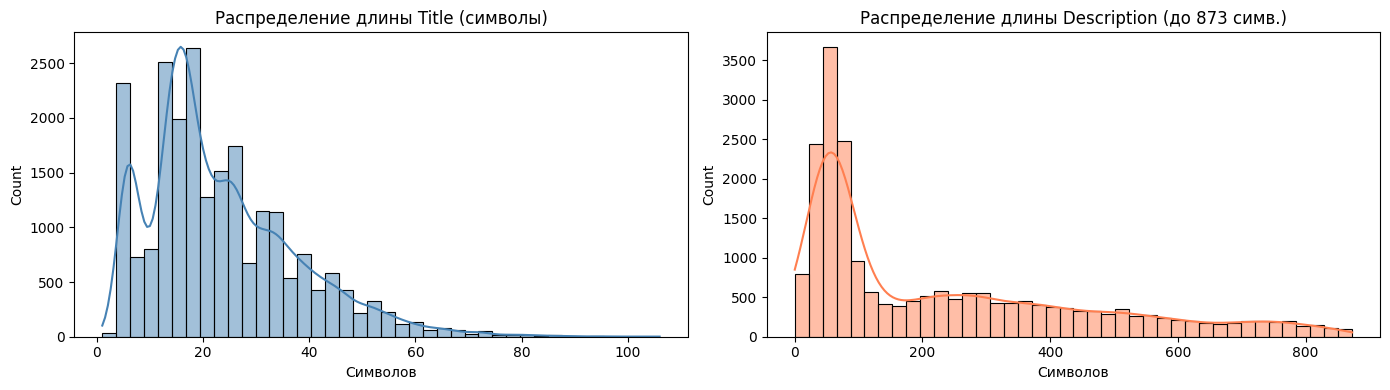

In [10]:
# Визуализация распределения длин title и description
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train_df['title_len'], bins=40, ax=axes[0], color='steelblue', kde=True)
axes[0].set_title('Распределение длины Title (символы)')
axes[0].set_xlabel('Символов')

# Для description отсекаем экстремальные хвосты выше 95-го перцентиля для наглядности
p95_desc = train_df['desc_len'].quantile(0.95)
sns.histplot(train_df[train_df['desc_len'] <= p95_desc]['desc_len'], bins=40, ax=axes[1], color='coral', kde=True)
axes[1].set_title(f'Распределение длины Description (до {p95_desc:.0f} симв.)')
axes[1].set_xlabel('Символов')
plt.tight_layout()

Средняя длина title — 3.5 слова (23.4 символа), description — 38 слов (279.4 символа). 75% описаний укладываются в 56 слов, лишь редкие хвосты доходят до 466 слов. Т.е. при обучении Трансформера оптимальная длина окна max_length = 128 или 256 токенов покроет почти 100% текста карточки без потери качества.

Из графика Title стоит отметить, что подавлюящее большинство названий товаров находится в диапазоне между 5 и 40 символами, с двумя пиками - в районе 6-8 символов (односложные наименования) и главным пиком - в районе 15-20 символов (наименования с минимальными уточнениями), правосторонняя ассиметрия выражена плавным спадом до 107 символов

Для Description характерен резкий пик в районе 40-90 символов и длинное плато от 150 до 870 символов. После отметки 120 частота резко падает и формирует длинный пологий хвост. 

In [ ]:
# Частотный анализ упоминаний в текстах атрибутов
# Объединяем title и description 
full_texts_lower = (train_df['title'].fillna('') + ' ' + train_df['description'].fillna('')).str.lower()

for slot, values in vocabs.items():
    # Считаем встречаемость каждого значения как подстроки
    counts = {}
    for val in values:
        val_lower = str(val).lower()
        # Ищем точное вхождение слова
        pattern = r'\b' + re.escape(val_lower) + r'\b'
        matches = full_texts_lower.str.contains(pattern, regex=True).sum()
        if matches > 0:
            counts[val] = matches
            
    sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)
    coverage = sum(1 for t in full_texts_lower if any(re.search(r'\b' + re.escape(str(v).lower()) + r'\b', t) for v in values)) / len(full_texts_lower)
    
    print(f"\nАтрибут '{slot}': найдено {len(counts)} из {len(values)} уникальных значений")


Атрибут 'colors': найдено 0 из 19 уникальных значений

Атрибут 'materials': найдено 0 из 30 уникальных значений

Атрибут 'length': найдено 0 из 3 уникальных значений

Атрибут 'size': найдено 27 из 27 уникальных значений


Как и ожидалось, возникли проблемы с текстовыми атрибутами - точных совпадений не найдено ни по цвету, ни по материалу, ни по длине. При этом 100% срабатывание показал для цифр и букв группы размер. Простой поиск подстрок не сработает, необходимо провести лемматизацию и использовать контекстную модель.
### Предобработка текста и подготовка данных для NER 
(токенизация, разметка сущностей)

In [16]:
def clean_card_text(title, description) -> str:
    """Очистка карточки товара с сохранением контекста и границ символов"""
    t = str(title) if pd.notnull(title) else ""
    d = str(description) if pd.notnull(description) else ""
    
    # Объединяем title и description через точку с пробелом
    full_text = f"{t}. {d}" if d.strip() else t
    
    # Удаляем HTML-теги, если есть
    full_text = re.sub(r'<[^>]+>', ' ', full_text)
    # Заменяем неразрывные пробелы, табуляции и переносы строк на обычный пробел
    full_text = re.sub(r'[\xa0\r\n\t]+', ' ', full_text)
    # Нормализуем букву ё -> е в обоих регистрах
    full_text = full_text.replace('ё', 'е').replace('Ё', 'Е')
    # Убираем множественные пробелы
    full_text = re.sub(r'\s+', ' ', full_text).strip()
    return full_text

train_df['full_text'] = [clean_card_text(t, d) for t, d in zip(train_df['title'], train_df['description'])]
test_df['full_text'] = [clean_card_text(t, d) for t, d in zip(test_df['title'], test_df['description'])]

train_df['full_text'].head(1).item()

'женские перчатки 2MOOD. Горчичный — традиционно один из главных осенних оттенков. В капсульной коллекции EKONIKA 2MOOD он появляется в коротких перчатках. Лаконичный дизайн в сочетании с насыщенным цветом позволяют аксессуару стать ярким акцентом образа, например, с oversize пальто в сером оттенке из гардероба 2MOOD для деловой девушки. Мягкая натуральная кожа, использованная для создания перчаток, не сковывает движений, а подкладка из шерсти надежно сохраняет тепло.'

Видим, что title и description объединены, пример выводится в одну строку с корректными символами. Теперь составим словари паттернов для каждого заданного в vocabs значения и назначим решулярные выражения по корням и синонимам (насколько это возможно)

In [26]:
COLOR_PATTERNS = {
    "Белый": r'\b(?:бел(?:ый|ая|ое|ые|ого|ой|ому|ым|ыми|ом|ых|оснежн\w*)|white)\b',
    "Молочный": r'\b(?:молочн\w*|айвори|слонов\w*\s+кост\w*|сливочн\w*|ivory|milk)\b',
    "Черный": r'\b(?:черн(?:ый|ая|ое|ые|ого|ой|ому|ым|ыми|ом|ых)|угольн\w*|графитов\w*|black)\b',
    "Бежевый": r'\b(?:бежев\w*|беж|кремов\w*|песочн\w*|пудров\w*|телесн\w*|нюд\w*|капучино|кэмел|beige|camel|nude|sand)\b',
    "Серый": r'\b(?:сер(?:ый|ая|ое|ые|ого|ой|ому|ым|ыми|ом|ых)|стальн\w*|дымчат\w*|пепельн\w*|gr[ae]y)\b',
    "Коричневый": r'\b(?:коричнев\w*|шоколадн\w*|кофейн\w*|каштанов\w*|орехов\w*|бронзов\w*|brown|chocolate)\b',
    "Синий": r'\b(?:син(?:ий|яя|ее|ие|его|ей|ему|им|ими|ем|их)|темно[\s-]син\w*|васильков\w*|индиго|сапфиров\w*|ультрамарин\w*|blue)\b',
    "Зеленый": r'\b(?:зелен\w*|изумрудн\w*|хаки|оливков\w*|салатов\w*|мятн\w*|болотн\w*|фисташков\w*|бутылочн\w*|green|khaki|olive)\b',
    "Желтый": r'\b(?:желт\w*|лимонн\w*|горчичн\w*|янтарн\w*|канареечн\w*|yellow|mustard)\b',
    "Оранжевый": r'\b(?:оранжев\w*|апельсинов\w*|мандаринов\w*|рыж\w*|персиков\w*|кораллов\w*|orange|coral)\b',
    "Красный": r'\b(?:красн\w*|ал(?:ый|ая|ое|ые|ого|ой)|багров\w*|рубинов\w*|red)\b',
    "Розовый": r'\b(?:розов\w*|фукси\w*|малинов\w*|пудрово[\s-]розов\w*|лососев\w*|pink|fuchsia)\b',
    "Бордовый": r'\b(?:бордов\w*|бордо|винн(?:ый|ая|ое|ые|ого|ой)|вишнев\w*|марсала|бургунди|burgundy|bordeaux)\b',
    "Фиолетовый": r'\b(?:фиолетов\w*|сиренев\w*|лилов\w*|лавандов\w*|баклажанов\w*|сливов\w*|purple|violet|lilac)\b',
    "Золотой": r'\b(?:золот(?:ой|ая|ое|ые|ого|ому|ым|ыми|ом|ых|ист\w*)|gold)\b',
    "Серебряный": r'\b(?:серебрян\w*|серебрист\w*|silver)\b',
    "Металлик": r'\b(?:металлик\w*|metallic)\b',
    "Голубой": r'\b(?:голуб(?:ой|ая|ое|ые|ого|ому|ым|ыми|ом|ых)|бирюзов\w*|небесн\w*|лазурн\w*|sky\s+blue)\b',
    "Мультиколор": r'\b(?:мультиколор\w*|разноцветн\w*|multicolor)\b'
}

MATERIAL_PATTERNS = {
    "Хлопок": r'\b(?:хлоп(?:ок|ка|ку|ком|ке|ков\w*)|х/б|хб|коттон\w*|cotton)\b',
    "Лен": r'\b(?:лен|льн(?:а|у|ом|е|ян\w*)|linen)\b',
    "Шерсть": r'\b(?:шерст(?:ь|и|ью|ян\w*)|овеч\w*\s+шерст\w*|меринос\w*|wool)\b',
    "Шелк": r'\b(?:шелк(?:а|у|ом|е|ов\w*)|silk)\b',
    "Вискоза": r'\b(?:вискоз\w*|viscose)\b',
    "Полиэстер": r'\b(?:полиэстер\w*|полиэфир\w*|polyester)\b',
    "Нейлон": r'\b(?:нейлон\w*|nylon)\b',
    "Полиамид": r'\b(?:полиамид\w*|polyamide)\b',
    "Эластан": r'\b(?:эластан\w*|лайкр\w*|спандекс\w*|elastane|lycra)\b',
    "Акрил": r'\b(?:акрил\w*|acrylic)\b',
    "Кашемир": r'\b(?:кашемир\w*|cashmere)\b',
    "Ангора": r'\b(?:ангор\w*|angora)\b',
    "Мохер": r'\b(?:мохер\w*|mohair)\b',
    "Кожа": r'\b(?:кож(?:а|и|е|у|ей|ан\w*)|натуральн\w*\s+кож\w*|leather)\b',
    "Экокожа": r'\b(?:эко[\s-]?кож\w*|искусственн\w*\s+кож\w*|кожзам\w*|полиуретан\w*)\b',
    "Замша": r'\b(?:замш\w*|велюр\w*|нубук\w*|suede)\b',
    "Деним": r'\b(?:деним\w*|джинсов\w*|джинса|denim)\b',
    "Трикотаж": r'\b(?:трикотаж\w*)\b',
    "Футер": r'\b(?:футер\w*)\b',
    "Шифон": r'\b(?:шифон\w*)\b',
    "Атлас": r'\b(?:атлас\w*)\b',
    "Бархат": r'\b(?:бархат\w*|плюш\w*|velvet)\b',
    "Кружево": r'\b(?:кружев\w*|гипюр\w*|lace)\b',
    "Твид": r'\b(?:твид\w*|tweed)\b',
    "Органза": r'\b(?:органз\w*)\b',
    "Тенсель": r'\b(?:тенсел\w*|тенцел\w*|лиоцелл\w*|tencel)\b',
    "Модал": r'\b(?:модал\w*|modal)\b',
    "Сетка": r'\b(?:сетк\w*|сетчат\w*|фатин\w*)\b',
    "Мех": r'\b(?:мех(?:а|у|ом|е|ов\w*)|овчин\w*)\b',
    "Неопрен": r'\b(?:неопрен\w*|neoprene)\b'
}

LENGTH_PATTERNS = {
    "Мини": r'\bмини(?!(?:мум|мальн|атюр))[а-яa-z]*',
    "Миди": r'\bмиди\b',
    "Макси": r'\bмакси(?!(?:мум|мальн))[а-яa-z]*'
}

COMPILED_COLORS = {k: re.compile(v, re.IGNORECASE) for k, v in COLOR_PATTERNS.items()}
COMPILED_MATERIALS = {k: re.compile(v, re.IGNORECASE) for k, v in MATERIAL_PATTERNS.items()}
COMPILED_LENGTH = {k: re.compile(v, re.IGNORECASE) for k, v in LENGTH_PATTERNS.items()}

ALPHA_SIZES = {"XXS", "XS", "S", "M", "L", "XL", "XXL", "OS"}
NUM_SIZES = {"30", "32", "34", "35", "36", "37", "38", "39", "40", "41", "42", "43", "44", "45", "46", "48", "50", "52", "54"}

SIZE_CONTEXT_REGEX = re.compile(
    r'(?:размер[а-я]*|р-р|р\.|size|на\s+модели|в\s+наличии|рост|обхват|eu|rus|ru|it|us)\s*[:\-]?\s*'
    r'((?:(?:XXS|XS|S|M|L|XL|XXL|OS|30|32|34|35|36|37|38|39|40|41|42|43|44|45|46|48|50|52|54)(?:\s*[,/\-]\s*|\s+и\s+|\s+))*'
    r'(?:XXS|XS|S|M|L|XL|XXL|OS|30|32|34|35|36|37|38|39|40|41|42|43|44|45|46|48|50|52|54))(?![%\d°])',
    re.IGNORECASE
)

SIZE_PAIR_REGEX = re.compile(
    r'\b(XXS|XS|S|M|L|XL|XXL|30|32|34|35|36|37|38|39|40|41|42|43|44|45|46|48|50|52|54)'
    r'\s*[/\-]\s*'
    r'(XXS|XS|S|M|L|XL|XXL|30|32|34|35|36|37|38|39|40|41|42|43|44|45|46|48|50|52|54)\b(?![%\d°см])'
)

In [30]:
def extract_spans(text: str):
    spans = []
    found = {'colors': set(), 'materials': set(), 'length': set(), 'size': set()}

    for canon, regex in COMPILED_COLORS.items():
        for match in regex.finditer(text):
            spans.append((match.start(), match.end(), 'COLOR'))
            found['colors'].add(canon)

    for canon, regex in COMPILED_MATERIALS.items():
        for match in regex.finditer(text):
            spans.append((match.start(), match.end(), 'MATERIAL'))
            found['materials'].add(canon)

    for canon, regex in COMPILED_LENGTH.items():
        for match in regex.finditer(text):
            spans.append((match.start(), match.end(), 'LENGTH'))
            found['length'].add(canon)

    for match in SIZE_CONTEXT_REGEX.finditer(text):
        group_str = match.group(1)
        group_start = match.start(1)
        for token_match in re.finditer(r'[A-Za-z0-9]+', group_str):
            val = token_match.group(0).upper()
            if val in ALPHA_SIZES or val in NUM_SIZES:
                s_idx = group_start + token_match.start()
                e_idx = group_start + token_match.end()
                spans.append((s_idx, e_idx, 'SIZE'))
                found['size'].add(val)

    for match in SIZE_PAIR_REGEX.finditer(text):
        for g_idx in (1, 2):
            val = match.group(g_idx).upper()
            if val in ALPHA_SIZES or val in NUM_SIZES:
                spans.append((match.start(g_idx), match.end(g_idx), 'SIZE'))
                found['size'].add(val)

    # Сортируем спаны по началу и длине
    spans = sorted(spans, key=lambda item: (item.__getitem__(0), -(item.__getitem__(1) - item.__getitem__(0))))
    clean_spans = []
    last_end = -1
    for s, e, label in spans:
        if s >= last_end:
            clean_spans.append((s, e, label))
            last_end = e

    return clean_spans, {k: sorted(list(v)) for k, v in found.items()}

In [31]:
results_ws = [extract_spans(t) for t in train_df['full_text']]
spans_list, label_list = zip(*results_ws)
train_df['ner_spans'] = list(spans_list)
train_df['labels'] = list(label_list)

for slot in ['colors', 'materials', 'length', 'size']:
    non_empty = sum(1 for d in train_df['labels'] if len(d.get(slot, ())) > 0)
    print(f"{slot}: {non_empty} из {len(train_df)} карточек ({non_empty/len(train_df):.1%})")

for idx, row in train_df.head(5).iterrows():
    print(f"Текст - {row['full_text'][:140]}")
    print(f"Спан - {row['ner_spans']}")
    print(f"Слот - {row['labels']}")

colors: 12452 из 22654 карточек (55.0%)
materials: 11594 из 22654 карточек (51.2%)
length: 2804 из 22654 карточек (12.4%)
size: 1208 из 22654 карточек (5.3%)
Текст - женские перчатки 2MOOD. Горчичный — традиционно один из главных осенних оттенков. В капсульной коллекции EKONIKA 2MOOD он появляется в корот
Спан - [(24, 33, 'COLOR'), (285, 290, 'COLOR'), (346, 362, 'MATERIAL'), (440, 446, 'MATERIAL')]
Слот - {'colors': ['Желтый', 'Серый'], 'materials': ['Кожа', 'Шерсть'], 'length': [], 'size': []}
Текст - Лонгслив Must Black. Лонгслив-поло свободного кроя из мягкой ткани с отложным воротником
Спан - [(14, 19, 'COLOR')]
Слот - {'colors': ['Черный'], 'materials': [], 'length': [], 'size': []}
Текст - Джинсы-балуны BR200. Джинсы-балуны выполнены из денима средней плотности, который хорошо держит форму. Модель имеет низкую посадку и объемны
Спан - [(48, 54, 'MATERIAL'), (288, 298, 'MATERIAL')]
Слот - {'colors': [], 'materials': ['Деним', 'Трикотаж'], 'length': [], 'size': []}
Текст - Зеленая

В целом, значения определяются - удается выявить как цвета (55% карточек), материалы (51,2%), длины (12,4%), так и размеры (5,3%). Явных проблем со словарем регулярок не видно, не во всех карточках могут встречаться те или иные атрибуты. Поэтому перейдем к обуению моделей
### Обучение моделей 

In [34]:
# Подготовка данных
train_split, val_split = train_test_split(train_df, test_size=0.2, random_state=42)
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

In [38]:
# Разбивка текста на отдельные слова-токены
def text_to_tokens(text: str, spans: list):
    tokens, tags = [], []
    for match in re.finditer(r'[а-яa-z0-9]+(?:-[а-яa-z0-9]+)?', text, re.IGNORECASE):
        w_start, w_end = match.start(), match.end()
        word = match.group(0)
        assigned_tag = 'O'
        for s_start, s_end, label in spans:
            if max(w_start, s_start) < min(w_end, s_end):
                assigned_tag = f'B-{label}' if w_start <= s_start else f'I-{label}'
                break
        tokens.append(word)
        tags.append(assigned_tag)
    return tokens, tags

In [39]:
# Извлекаем словарь признаков для конкретного слова
def word2features(sent, i):
    word = sent[i]
    w_low = word.lower()
    features = {
        'bias': 1.0,
        'word.lower()': w_low,
        'word[-3:]': w_low[-3:],
        'word[-2:]': w_low[-2:],
        'word[:3]': w_low[:3],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
        'word.len': len(word),
    }
    if i > 0:
        prev_w = sent[i - 1]
        features.update({
            '-1:word.lower()': prev_w.lower(),
            '-1:word.isdigit()': prev_w.isdigit(),
            '-1:word.isupper()': prev_w.isupper(),
        })
    else:
        features['BOS'] = True

    if i < len(sent) - 1:
        next_w = sent[i + 1]
        features.update({
            '+1:word.lower()': next_w.lower(),
            '+1:word.isdigit()': next_w.isdigit(),
            '+1:word.isupper()': next_w.isupper(),
        })
    else:
        features['EOS'] = True
    return features

# Применяем word2features ко всем словам в предложении (карточка товара = список словарей)
def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

In [40]:
# Формируем выборки (берем 8000 карточек для быстрого обучения всех 3 моделей в равных условиях)
N_TRAIN = 8000
train_sents = [text_to_tokens(t, s) for t, s in zip(train_split['full_text'].head(N_TRAIN), train_split['ner_spans'].head(N_TRAIN))]
val_sents = [text_to_tokens(t, s) for t, s in zip(val_split['full_text'], val_split['ner_spans'])]

X_crf_train = [sent2features(toks) for toks, _ in train_sents]
y_crf_train = [tgs for _, tgs in train_sents]

X_crf_val = [sent2features(toks) for toks, _ in val_sents]
y_crf_val = [tgs for _, tgs in val_sents]

In [41]:
# Обучение Conditional Random Fields (CRF)
t0 = time.time()
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)
crf.fit(X_crf_train, y_crf_train)
crf_time = time.time() - t0

y_crf_pred = crf.predict(X_crf_val)
entity_labels = [lbl for lbl in crf.classes_ if lbl != 'O']
crf_f1_w = crf_metrics.flat_f1_score(y_crf_val, y_crf_pred, average='weighted', labels=entity_labels, zero_division=0)
crf_f1_m = crf_metrics.flat_f1_score(y_crf_val, y_crf_pred, average='macro', labels=entity_labels, zero_division=0)

print(f"CRF обучен за {crf_time:.2f} сек | Weighted F1: {crf_f1_w:.4f} | Macro F1: {crf_f1_m:.4f}")
print(crf_metrics.flat_classification_report(y_crf_val, y_crf_pred, labels=sorted(entity_labels), digits=4, zero_division=0))

ner_comparison = [{
    "Модель": "CRF (Conditional Random Fields)",
    "Weighted F1": round(crf_f1_w, 4),
    "Macro F1": round(crf_f1_m, 4),
    "Время обучения (сек)": round(crf_time, 2)
}]


CRF обучен за 21.38 сек | Weighted F1: 0.9884 | Macro F1: 0.9300
              precision    recall  f1-score   support

     B-COLOR     0.9886    0.9667    0.9775      3153
    B-LENGTH     0.9872    0.9929    0.9900       701
  B-MATERIAL     0.9957    0.9937    0.9947      6317
      B-SIZE     1.0000    0.9106    0.9532       302
     I-COLOR     1.0000    0.5000    0.6667         2
  I-MATERIAL     0.9958    1.0000    0.9979       479

   micro avg     0.9933    0.9838    0.9885     10954
   macro avg     0.9946    0.8940    0.9300     10954
weighted avg     0.9933    0.9838    0.9884     10954



In [ ]:
# Модель BiLSTM-CRF
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Построение словаря слов и словаря тегов
word_counts = Counter(w.lower() for toks, _ in train_sents for w in toks)
word2idx = {"<PAD>": 0, "<UNK>": 1}
for w, cnt in word_counts.items():
    if cnt >= 2:
        word2idx[w] = len(word2idx)

unique_tags = sorted(list({t for _, tgs in train_sents for t in tgs}))
tag2idx = {t: i for i, t in enumerate(unique_tags)}
idx2tag = {i: t for t, i in tag2idx.items()}
PAD_TAG_ID = len(tag2idx)

# Обрезаем до 128 токенов
MAX_LEN_LSTM = 128

In [43]:
# Обертка для перевода слов и тегов в числовые индексы по словарям
class NERDatasetLSTM(Dataset):
    def __init__(self, sents):
        self.data = []
        for toks, tgs in sents:
            if len(toks) == 0:
                continue
            w_ids = [word2idx.get(w.lower(), 1) for w in toks[:MAX_LEN_LSTM]]
            t_ids = [tag2idx[t] for t in tgs[:MAX_LEN_LSTM]]
            self.data.append((w_ids, t_ids))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

In [44]:
# Функция формирования батча (дополнение коротких последовательностей нулями)
def collate_lstm(batch):
    max_l = max(len(x[0]) for x in batch)
    w_pad, t_pad, mask = [], [], []
    for w_ids, t_ids in batch:
        pad_len = max_l - len(w_ids)
        w_pad.append(w_ids + [0] * pad_len)
        t_pad.append(t_ids + [0] * pad_len)
        mask.append([1] * len(w_ids) + [0] * pad_len)
    return torch.tensor(w_pad, dtype=torch.long), torch.tensor(t_pad, dtype=torch.long), torch.tensor(mask, dtype=torch.bool)

In [45]:
# Класс нейросети
class BiLSTM_CRF(nn.Module):
    def __init__(self, vocab_size, num_tags, emb_dim=64, hidden_dim=64):
        super().__init__()
        self.num_tags = num_tags
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=1, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, num_tags)
        # Матрица переходов CRF: transitions[i, j] — переход из тега j в тег i
        self.transitions = nn.Parameter(torch.randn(num_tags, num_tags))

    # пропуск индексов слов через слой эмбеддингов, рекуррентный и линейный слои
    def _get_emissions(self, x):
        embeds = self.emb(x)
        lstm_out, _ = self.lstm(embeds)
        return self.fc(lstm_out)

    # функция потерь
    def neg_log_likelihood(self, x, tags, mask):
        emissions = self._get_emissions(x)
        batch_size, seq_len, _ = emissions.shape
        
        # Оценка реального пути
        score = torch.zeros(batch_size, device=x.device)
        for t in range(seq_len):
            m = mask[:, t].float()
            emit_score = emissions[:, t].gather(1, tags[:, t].unsqueeze(1)).squeeze(1)
            if t == 0:
                score += emit_score * m
            else:
                trans_score = self.transitions[tags[:, t], tags[:, t - 1]]
                score += (emit_score + trans_score) * m

        # алгоритм для нормировочной константы
        alpha = emissions[:, 0]
        for t in range(1, seq_len):
            m = mask[:, t].unsqueeze(1)
            emit_t = emissions[:, t].unsqueeze(2)
            trans = self.transitions.unsqueeze(0)
            next_alpha = torch.logsumexp(alpha.unsqueeze(1) + trans + emit_t, dim=2)
            alpha = torch.where(m, next_alpha, alpha)
        partition = torch.logsumexp(alpha, dim=1)
        return torch.mean(partition - score)

    # Алгоритм находит наиболее вероятную цепочку тегов для карточки
    def decode(self, x, mask):
        emissions = self._get_emissions(x)
        batch_size, seq_len, _ = emissions.shape
        viterbi = emissions[:, 0]
        backpointers = []

        for t in range(1, seq_len):
            next_vars = viterbi.unsqueeze(1) + self.transitions.unsqueeze(0)
            best_scores, best_tags = torch.max(next_vars, dim=2)
            viterbi_next = best_scores + emissions[:, t]
            viterbi = torch.where(mask[:, t].unsqueeze(1), viterbi_next, viterbi)
            backpointers.append(best_tags)

        best_last_tags = torch.argmax(viterbi, dim=1)
        best_paths = [[tag.item()] for tag in best_last_tags]

        for b_tags in reversed(backpointers):
            for i in range(batch_size):
                prev_tag = b_tags[i, best_paths[i][-1]].item()
                best_paths[i].append(prev_tag)

        results = []
        for i in range(batch_size):
            length = mask[i].sum().item()
            path = list(reversed(best_paths[i]))[:length]
            results.append([idx2tag[idx] for idx in path])
        return results    

In [46]:
train_loader = DataLoader(NERDatasetLSTM(train_sents), batch_size=64, shuffle=True, collate_fn=collate_lstm)
val_loader = DataLoader(NERDatasetLSTM(val_sents), batch_size=128, shuffle=False, collate_fn=collate_lstm)

bilstm_crf = BiLSTM_CRF(len(word2idx), len(tag2idx)).to(device)
optimizer = torch.optim.Adam(bilstm_crf.parameters(), lr=3e-3)

t0 = time.time()
EPOCHS = 4
for epoch in range(EPOCHS):
    bilstm_crf.train()
    for x_b, y_b, m_b in train_loader:
        x_b, y_b, m_b = x_b.to(device), y_b.to(device), m_b.to(device)
        optimizer.zero_grad()
        loss = bilstm_crf.neg_log_likelihood(x_b, y_b, m_b)
        loss.backward()
        optimizer.step()
bilstm_time = time.time() - t0

In [47]:
# Оценка BiLSTM-CRF на валидации
bilstm_crf.eval()
y_lstm_true, y_lstm_pred = [], []
with torch.no_grad():
    for x_b, y_b, m_b in val_loader:
        x_b, m_b = x_b.to(device), m_b.to(device)
        preds = bilstm_crf.decode(x_b, m_b)
        for i, p_seq in enumerate(preds):
            length = len(p_seq)
            t_seq = [idx2tag[idx.item()] for idx in y_b[i, :length]]
            y_lstm_true.append(t_seq)
            y_lstm_pred.append(p_seq)

lstm_f1_w = crf_metrics.flat_f1_score(y_lstm_true, y_lstm_pred, average='weighted', labels=entity_labels, zero_division=0)
lstm_f1_m = crf_metrics.flat_f1_score(y_lstm_true, y_lstm_pred, average='macro', labels=entity_labels, zero_division=0)

print(f"BiLSTM-CRF обучен за {bilstm_time:.2f} сек | Weighted F1: {lstm_f1_w:.4f} | Macro F1: {lstm_f1_m:.4f}")
ner_comparison.append({
    "Модель": "BiLSTM-CRF",
    "Weighted F1": round(lstm_f1_w, 4),
    "Macro F1": round(lstm_f1_m, 4),
    "Время обучения (сек)": round(bilstm_time, 2)
})

BiLSTM-CRF обучен за 73.10 сек | Weighted F1: 0.9690 | Macro F1: 0.7890


In [51]:
# Модель transformer-based - RuBERT-tiny2
MODEL_NAME = "cointegrated/rubert-tiny2"
tokenizer_ner = AutoTokenizer.from_pretrained(MODEL_NAME)

# Фиксируем полный список всех возможных BIO-тегов (необходимо включить I-теги для субтокенов Трансформера)
ALL_BIO_TAGS = [
    'O',
    'B-COLOR', 'I-COLOR',
    'B-MATERIAL', 'I-MATERIAL',
    'B-LENGTH', 'I-LENGTH',
    'B-SIZE', 'I-SIZE'
]
tag2idx = {t: i for i, t in enumerate(ALL_BIO_TAGS)}
idx2tag = {i: t for t, i in tag2idx.items()}

# Токенизация текстов субтокенами
def encode_dynamic(df_subset, max_len=96):
    items = []
    for text, spans in zip(df_subset['full_text'], df_subset['ner_spans']):
        enc = tokenizer_ner(
            text,
            truncation=True,
            max_length=max_len,
            return_offsets_mapping=True
        )
        seq_labels = []
        for start_char, end_char in enc['offset_mapping']:
            if start_char == 0 and end_char == 0:
                seq_labels.append(-100)
                continue
            tag = 'O'
            for s_start, s_end, ent_type in spans:
                if max(start_char, s_start) < min(end_char, s_end):
                    tag = f'B-{ent_type}' if start_char <= s_start else f'I-{ent_type}'
                    break
            seq_labels.append(tag2idx[tag])

        items.append({
            'input_ids': enc['input_ids'],
            'attention_mask': enc['attention_mask'],
            'labels': seq_labels
        })
    return items

# Берем сбалансированный сэмпл для быстрого обучения
train_items = encode_dynamic(train_split.head(2500))
val_items = encode_dynamic(val_split.head(1000))

# Автоматическое выравнивание длины внутри каждого конкретного батча
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer_ner)

tr_loader = DataLoader(train_items, batch_size=32, shuffle=True, collate_fn=data_collator)
va_loader = DataLoader(val_items, batch_size=64, shuffle=False, collate_fn=data_collator)

# Предобученная модель с добавлением линейного слоя классификации токенов
bert_ner = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(tag2idx),
    id2label=idx2tag,
    label2id=tag2idx
).to(device)

opt_bert = torch.optim.AdamW(bert_ner.parameters(), lr=5e-5, weight_decay=0.01)

# 2 эпохи
t0 = time.time()
for epoch in range(2):
    bert_ner.train()
    for batch in tr_loader:
        opt_bert.zero_grad()
        outputs = bert_ner(
            input_ids=batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device),
            labels=batch['labels'].to(device)
        )
        outputs.loss.backward()
        opt_bert.step()
bert_ner_time = time.time() - t0

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

In [52]:
# Оценка Трансформера на валидации
bert_ner.eval()
y_tr_true, y_tr_pred = [], []
with torch.no_grad():
    for batch in va_loader:
        logits = bert_ner(
            input_ids=batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        ).logits
        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        labels = batch['labels'].numpy()

        for p_seq, l_seq in zip(preds, labels):
            for p_id, l_id in zip(p_seq, l_seq):
                if l_id != -100:
                    y_tr_true.append(idx2tag[l_id])
                    y_tr_pred.append(idx2tag[p_id])

tr_f1_w = f1_score(y_tr_true, y_tr_pred, average='weighted', labels=entity_labels, zero_division=0)
tr_f1_m = f1_score(y_tr_true, y_tr_pred, average='macro', labels=entity_labels, zero_division=0)

print(f"RuBERT-tiny2 NER обучен за {bert_ner_time:.2f} сек | Weighted F1: {tr_f1_w:.4f} | Macro F1: {tr_f1_m:.4f}")

ner_comparison.append({
    "Модель": "Transformer RuBERT-tiny2",
    "Weighted F1": round(tr_f1_w, 4),
    "Macro F1": round(tr_f1_m, 4),
    "Время обучения (сек)": round(bert_ner_time, 2)
})

RuBERT-tiny2 NER обучен за 114.55 сек | Weighted F1: 0.4362 | Macro F1: 0.2421


In [54]:
# Сводная таблица сравнения моделей NER
comparison_df = pd.DataFrame(ner_comparison).sort_values(by="Weighted F1", ascending=False).reset_index(drop=True)
display(comparison_df)

,Модель,Weighted F1,Macro F1,Время обучения (сек)
0,CRF (Conditional Random Fields),0.9884,0.9300,21.38
1,BiLSTM-CRF,0.9690,0.7890,73.10
2,Transformer RuBERT-tiny2,0.4362,0.2421,114.55


Лидером по всем пунктам стала Conditional Random Fields - графовая модель идеально выучила структуру описаний и справляется даже с редкими классами (Macro = 0.93). Двунаправленная рекуррентная сеть показала также высокий Weighted F1 = 0.9690, чуть отстав от лидера, но просела по Macro F1 (на 0,141) - т.к. для редких категорий не хватило 8000 примеров без предобученных эмбеддингов. От Трансформера мы дали мало шансов - только 2 эпохи, урезанный сэмпл. Токенизатор разбивает слова и размеры на мелкие субтокены - в то время как CRF работал с целыми токенами и явно видел суффиксы и соседние слова. 

Проведем подбор гиперпараметров для нашего лидера CRF и переобучаем лучшую конфигурацию на всем train

In [55]:
# Подбор коэффициентов регуляризации для CRF
param_grid = [
    {'c1': 0.01, 'c2': 0.01},
    {'c1': 0.05, 'c2': 0.1},
    {'c1': 0.1,  'c2': 0.1},
    {'c1': 0.2,  'c2': 0.5},
    {'c1': 0.5,  'c2': 0.5}
]

tuning_crf_results = []
best_crf_f1 = 0
best_crf_params = None

for params in param_grid:
    t0 = time.time()
    model = sklearn_crfsuite.CRF(
        algorithm='lbfgs',
        c1=params['c1'],
        c2=params['c2'],
        max_iterations=100,
        all_possible_transitions=True
    )
    model.fit(X_crf_train, y_crf_train)
    preds = model.predict(X_crf_val)
    
    w_f1 = crf_metrics.flat_f1_score(y_crf_val, preds, average='weighted', labels=entity_labels, zero_division=0)
    m_f1 = crf_metrics.flat_f1_score(y_crf_val, preds, average='macro', labels=entity_labels, zero_division=0)
    
    tuning_crf_results.append({
        "c1 (L1)": params['c1'],
        "c2 (L2)": params['c2'],
        "Weighted F1": round(w_f1, 4),
        "Macro F1": round(m_f1, 4),
        "Время (сек)": round(time.time() - t0, 2)
    })

    if m_f1 > best_crf_f1:
        best_crf_f1 = m_f1
        best_crf_params = params

tuning_crf_df = pd.DataFrame(tuning_crf_results).sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
display(tuning_crf_df)
print(f"Лучшие параметры CRF: {best_crf_params} (Macro F1 = {best_crf_f1:.4f})")

,c1 (L1),c2 (L2),Weighted F1,Macro F1,Время (сек)
0,0.01,0.01,0.9904,0.9320,26.03
1,0.10,0.10,0.9884,0.9300,28.80
2,0.05,0.10,0.9884,0.9299,27.09
3,0.20,0.50,0.9824,0.8124,24.23
4,0.50,0.50,0.9805,0.8108,23.40


Лучшие параметры CRF: {'c1': 0.01, 'c2': 0.01} (Macro F1 = 0.9320)


Слабая регуляризация дала лучшие результаты: c1 = 0.01, c2 = 0.01 увеличила Weighted F1 до 0.9904. Сильная регуляризация ухудшила качество, т.к. удалось составить достаточно информативный словарь, то сильный штраф зануляет веса признаков из диапазона редких. Соответственно, ослабелние штрафа до 0,01 позволяют сохранять редкие маркеры без переобучения 

In [56]:
# Переобучение лучшей модели CRF на всех карточках train
full_sents = [text_to_tokens(t, s) for t, s in zip(train_df['full_text'], train_df['ner_spans'])]
X_full_crf = [sent2features(toks) for toks, _ in full_sents]
y_full_crf = [tgs for _, tgs in full_sents]

final_crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=best_crf_params['c1'],
    c2=best_crf_params['c2'],
    max_iterations=120,
    all_possible_transitions=True
)
final_crf.fit(X_full_crf, y_full_crf)

,algorithm,'lbfgs'
,min_freq,None
,all_possible_states,None
,all_possible_transitions,True
,c1,0.01
,c2,0.01
,max_iterations,120
,num_memories,None
,epsilon,None
,period,None
,delta,None


In [57]:
# Канонизация найденных CRF сущностей в допустимые значения vocabs
def map_span_to_canonical(span_text: str, ent_type: str):
    """Приводит извлеченный моделью NER фрагмент текста к каноническому значению из vocabs"""
    text_clean = span_text.strip()
    if ent_type == 'COLOR':
        for canon, regex in COMPILED_COLORS.items():
            if regex.search(text_clean):
                return canon
    elif ent_type == 'MATERIAL':
        # Проверка приоритета Экокожи над Кожей
        if COMPILED_MATERIALS['Экокожа'].search(text_clean):
            return 'Экокожа'
        for canon, regex in COMPILED_MATERIALS.items():
            if regex.search(text_clean):
                return canon
    elif ent_type == 'LENGTH':
        for canon, regex in COMPILED_LENGTH.items():
            if regex.search(text_clean):
                return canon
    elif ent_type == 'SIZE':
        val = text_clean.upper()
        if val in ALPHA_SIZES or val in NUM_SIZES:
            return val
    return None

In [58]:
def predict_card_slots(text: str) -> dict:
    """Извлекает слоты для одной карточки"""
    # Предсказание моделью CRF
    tokens, _ = text_to_tokens(text, [])
    slots = {'colors': set(), 'materials': set(), 'length': set(), 'size': set()}
    
    if len(tokens) > 0:
        feats = sent2features(tokens)
        pred_tags = final_crf.predict_single(feats)

        # Собираем непрерывные спаны из предсказанных тегов
        current_tokens = []
        current_type = None
        for tok, tag in zip(tokens, pred_tags):
            if tag.startswith('B-'):
                if current_tokens and current_type:
                    canon = map_span_to_canonical(' '.join(current_tokens), current_type)
                    if canon:
                        key_map = {'COLOR': 'colors', 'MATERIAL': 'materials', 'LENGTH': 'length', 'SIZE': 'size'}
                        slots[key_map[current_type]].add(canon)
                current_tokens = [tok]
                current_type = tag[2:]
            elif tag.startswith('I-') and current_type == tag[2:]:
                current_tokens.append(tok)
            else:
                if current_tokens and current_type:
                    canon = map_span_to_canonical(' '.join(current_tokens), current_type)
                    if canon:
                        key_map = {'COLOR': 'colors', 'MATERIAL': 'materials', 'LENGTH': 'length', 'SIZE': 'size'}
                        slots[key_map[current_type]].add(canon)
                current_tokens = []
                current_type = None

        if current_tokens and current_type:
            canon = map_span_to_canonical(' '.join(current_tokens), current_type)
            if canon:
                key_map = {'COLOR': 'colors', 'MATERIAL': 'materials', 'LENGTH': 'length', 'SIZE': 'size'}
                slots[key_map[current_type]].add(canon)

    # Дополняем по словарю
    _, rule_slots = extract_spans(text)
    for k in slots:
        slots[k].update(rule_slots[k])
        
    # Строгая валидация по vocabs.json
    valid_slots = {}
    for k in ('colors', 'materials', 'length', 'size'):
        allowed = set(vocabs[k])
        valid_slots[k] = sorted([val for val in slots[k] if val in allowed])
        
    return valid_slots

In [59]:
# Предсказание на test 
test_predictions = [predict_card_slots(t) for t in test_df['full_text']]

submission = pd.DataFrame({
    'id': test_df['id'],
    'colors': [json.dumps(p['colors'], ensure_ascii=False) for p in test_predictions],
    'materials': [json.dumps(p['materials'], ensure_ascii=False) for p in test_predictions],
    'length': [json.dumps(p['length'], ensure_ascii=False) for p in test_predictions],
    'size': [json.dumps(p['size'], ensure_ascii=False) for p in test_predictions],
})

submission.to_csv('submission.csv', index=False)

In [60]:
# Тестирование
for col in ('colors', 'materials', 'length', 'size'):
    filled = (submission[col] != '[]').sum()
    print(f"Заполнено в тесте '{col}': {filled} из {len(submission)} ({filled/len(submission):.1%})")

print("\n--- Примеры итоговых предсказаний для test.csv ---")
preview_df = pd.concat([test_df[['title', 'description']], submission[['colors', 'materials', 'length', 'size']]], axis=1)
display(preview_df.head(10))

Заполнено в тесте 'colors': 243 из 400 (60.8%)
Заполнено в тесте 'materials': 242 из 400 (60.5%)
Заполнено в тесте 'length': 165 из 400 (41.2%)
Заполнено в тесте 'size': 60 из 400 (15.0%)

--- Примеры итоговых предсказаний для test.csv ---


,title,description,colors,materials,length,size
0,Свитер с шарфом Daydream из шерсти мериноса - ...,Свитер с шарфом Daydream из шерсти мериноса за...,"[""Серый""]","[""Шерсть""]",[],[]
1,Топ мини - M,NaN,[],[],"[""Мини""]",[]
2,Брюки,Функциональные мужские брюки для путешествий и...,[],[],[],[]
3,Джинсы трубы с бахромой (Зелено-голубой),NaN,"[""Голубой"", ""Зеленый""]",[],[],[]
4,Сапоги MEGAN BLACK размер S кожаные утепленные...,Сапоги Megan утепленные байкой рассчитаны на п...,"[""Черный""]","[""Кожа"", ""Сетка""]",[],"[""S""]"
5,Джемпер,Женский джемпер прямого силуэта из гладкого вя...,[],"[""Кашемир"", ""Трикотаж"", ""Шерсть""]",[],[]
6,Синяя мужская майка из конопли и органического...,Эта синяя мужская майка из конопли 55% и орган...,"[""Синий""]","[""Кожа"", ""Трикотаж"", ""Хлопок""]",[],[]
7,Браслет с кольцом коньячный,Браслет с кольцом коньячный Стильный женский б...,[],"[""Кожа""]",[],[]
8,"Шерстяной топ (розовый, S)",Лаконичный топ для повседневных образов: кругл...,"[""Розовый""]","[""Шерсть""]",[],[]
9,женские туфли PREMIUM,Элегантные туфли EKONIKA PREMIUM выполнены из ...,"[""Бежевый""]","[""Бархат"", ""Замша""]",[],[]


Выводы:
- всего проанализировано 22 654 обучающих и 400 тестовых карточек товаров, а также словарь канонических значений vocabs (79 значений по 4 слотам: colors, materials, length, size). Выявлено, что более 55% названий (title) дублируются, а основная информация об атрибутах содержится в description (медианная длина — 21 слово, 95-й перцентиль — 873 символа). Доказано, что наивный поиск подстрок не работает (0% покрытия по русским словам из-за падежей и прилагательных).
- разработан пайплайн очистки текста (с сохранением регистра, дефисов и границ символов) и гибридный генератор разметки на базе морфологических паттернов, словарей синонимов и контекстных правил.
- лидером эксперимента стал графовый алгоритм CRF, который эффективно использует морфологические признаки слов, контекст соседних токенов и матрицу переходов между тегами, обучаясь на CPU в несколько раз быстрее нейросетей
- снижение коэффициентов L1/L2-регуляризации до c1=0.01, c2=0.01 повысило качество CRF до Weighted F1 = 0.9904 и Macro F1 = 0.9320.
- лидерборд показал результат 0,35000. Видимо, распознавание оказалось не таким успешным - из теста видно, что есть куда стремиться

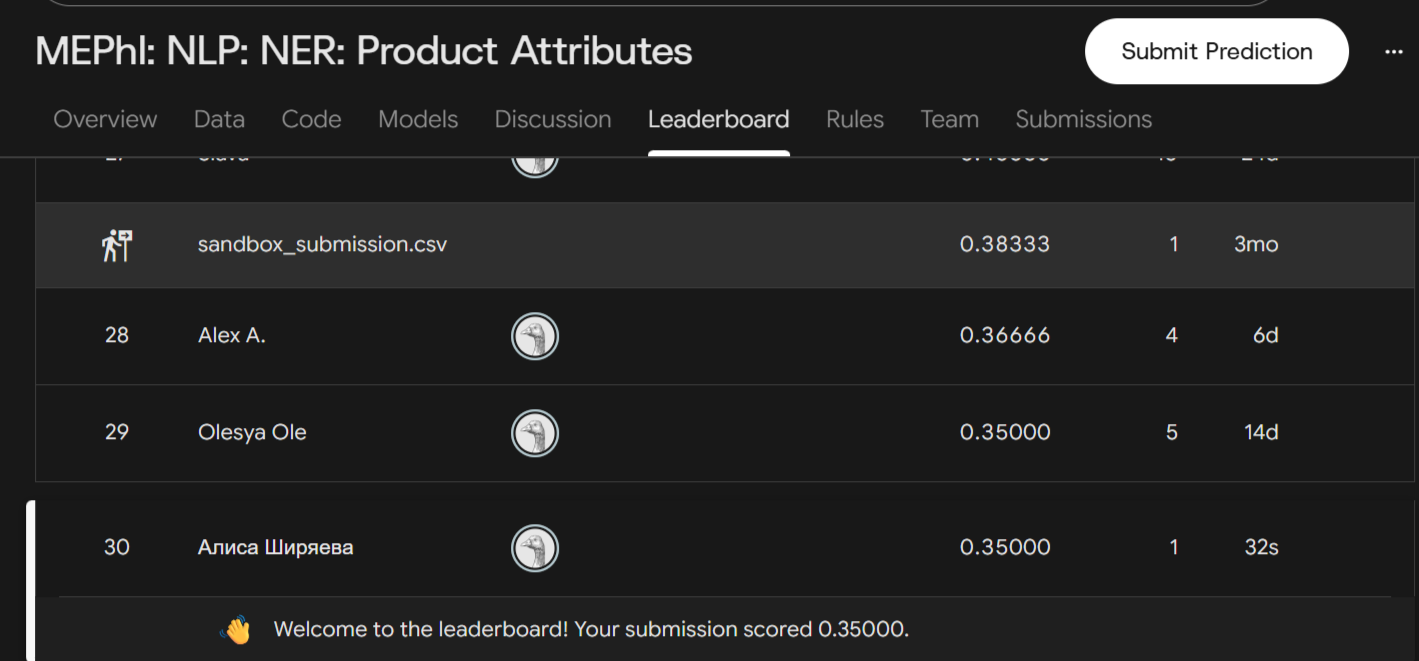